In [2]:
# 2. Load and inspect

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df = pd.read_csv("tips.csv")
display(df.head())
print( df.shape)
df.info()

print("Missing values")
display(df.isna().sum())



,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


(244, 7)
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB
Missing values


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [19]:
df["is_female"] = np.where(df["sex"] == "Female", 1, 0)

df["day_num"] = df["day"].map({
    "Thur": 0,
    "Fri": 1,
    "Sat": 2,
    "Sun": 3
})

df["is_smoker"] = np.where(df["smoker"] == "Yes", 1, 0)

df["is_dinner"] = np.where(df["time"] == "Dinner", 1, 0)

In [22]:
df[["total_bill", "tip", "is_female", "is_smoker", "day_num", "is_dinner" , "size"]].head()

,total_bill,tip,is_female,is_smoker,day_num,is_dinner,size
0,16.99,1.01,1,0,3,1,2
1,10.34,1.66,0,0,3,1,3
2,21.01,3.50,0,0,3,1,3
3,23.68,3.31,0,0,3,1,2
4,24.59,3.61,1,0,3,1,4


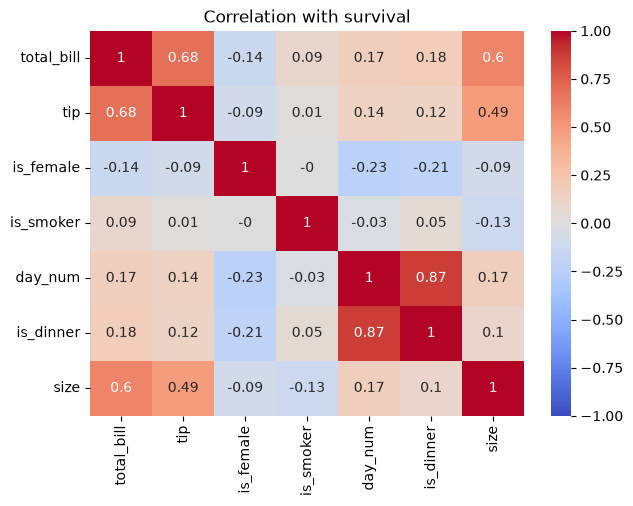

In [23]:
cols = ["total_bill", "tip", "is_female", "is_smoker", "day_num", "is_dinner" , "size"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation with survival")
plt.show()

Correlation: 0.68


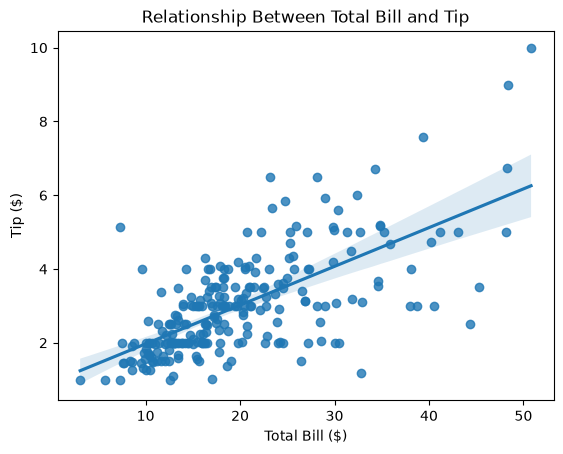

In [24]:
#q1: higher bill means higher tip?

correlation = df["total_bill"].corr(df["tip"])
print("Correlation:", round(correlation, 2))

# Visualize relationship
sns.regplot(data=df, x="total_bill", y="tip")

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

Average tip for females: 2.83
Average tip for males: 3.09
Correlation: -0.09


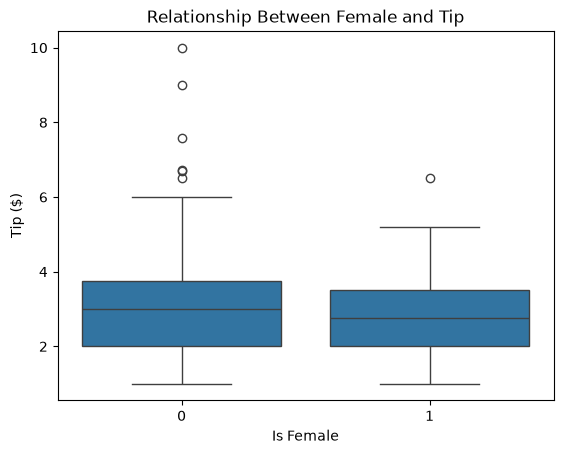

In [32]:
# q2: Do females tip more than males?
female_tips = df[df["is_female"] == 1]["tip"]
male_tips = df[df["is_female"] == 0]["tip"]

print("Average tip for females:", round(female_tips.mean(), 2))
print("Average tip for males:", round(male_tips.mean(), 2))

correlation = df["is_female"].corr(df["tip"])
print("Correlation:", round(correlation, 2))

# Visualize relationship
sns.boxplot(data=df, x="is_female", y="tip")
plt.title("Relationship Between Female and Tip")
plt.xlabel("Is Female")
plt.ylabel("Tip ($)")
plt.show()

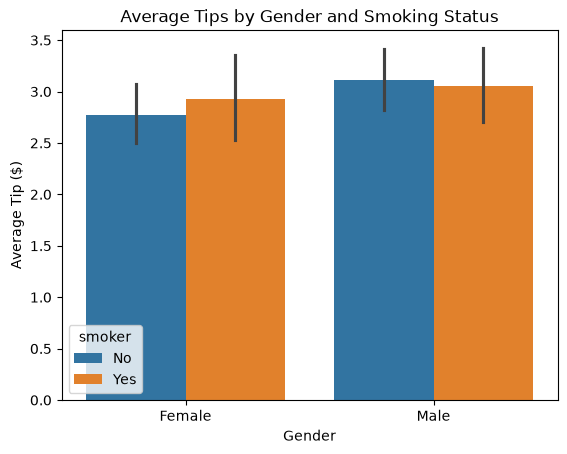

In [34]:
#q3 smoking affects tip amount?
sns.barplot(
    data=df,
    x="sex",
    y="tip",
    hue="smoker",
)

plt.title("Average Tips by Gender and Smoking Status")
plt.xlabel("Gender")
plt.ylabel("Average Tip ($)")
plt.show()